# Classification : logistic regression à la main et frontières

**Objectifs.** Dériver et coder une logistic regression binaire, visualiser une frontière linéaire, comparer à KNN, arbre, SVM RBF et Naive Bayes sur le même split. Durée : 90–120 min.

## 1. Un problème non linéaire en deux dimensions

Les deux caractéristiques artificielles forment deux croissants. La logistic regression combine des variables linéairement puis passe par sigmoid ; une seule frontière droite ne peut donc pas suivre parfaitement les deux courbes.

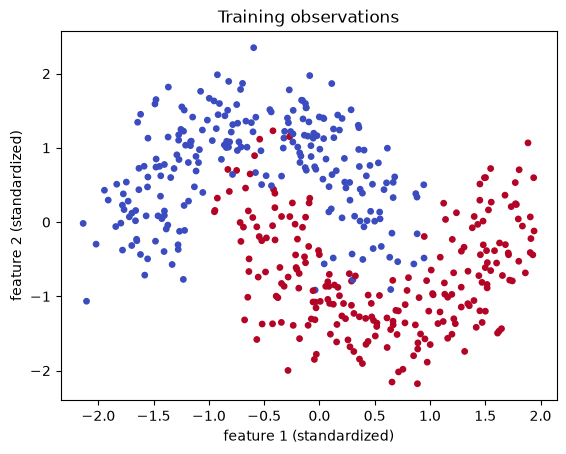

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X, y = make_moons(n_samples=600, noise=0.22, random_state=11)
x_train, x_test, y_train, y_test = train_test_split(X, y, stratify=y, test_size=0.25, random_state=11)
scaler = StandardScaler().fit(x_train)
x_train_scaled = scaler.transform(x_train)
x_test_scaled = scaler.transform(x_test)
plt.scatter(x_train_scaled[:, 0], x_train_scaled[:, 1], c=y_train, cmap='coolwarm', s=15)
plt.xlabel('feature 1 (standardized)'); plt.ylabel('feature 2 (standardized)'); plt.title('Training observations')
plt.show()

### Du score linéaire à la probabilité

La logistic regression calcule d'abord un score `z = x @ w + b` (un nombre par ligne), puis `sigmoid(z) = 1/(1+exp(-z))`. Le seuil `0.5` correspond à `z=0`. Modifier le seuil change le compromis entre faux positifs et faux négatifs, sans réentraîner le modèle. Le graphique illustre cette transformation, pas un calibrage garanti.

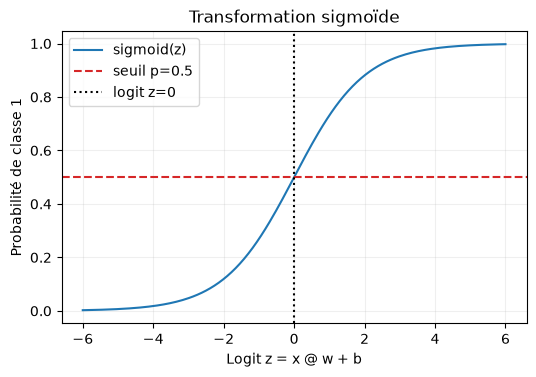

In [ ]:
logit_grid = np.linspace(-6, 6, 200)
sigmoid_grid = 1 / (1 + np.exp(-logit_grid))
fig, ax = plt.subplots(figsize=(6, 3.8))
ax.plot(logit_grid, sigmoid_grid, label='sigmoid(z)')
ax.axhline(0.5, color='tab:red', linestyle='--', label='seuil p=0.5')
ax.axvline(0, color='black', linestyle=':', label='logit z=0')
ax.set(xlabel='Logit z = x @ w + b', ylabel='Probabilité de classe 1', title='Transformation sigmoïde')
ax.legend(); ax.grid(alpha=0.2); plt.show()

## 2. Implémentation NumPy et gradients

Pour logits `z = X @ w + b`, la probabilité est `sigmoid(z)`. La cross-entropy binaire mène au gradient `X.T @ (p-y)/n` et `mean(p-y)` pour le biais. La standardisation est ajustée sur train seulement pour stabiliser l’optimisation.

In [ ]:
def sigmoid(logits):
    return 1 / (1 + np.exp(-np.clip(logits, -30, 30)))

weight = np.zeros(x_train_scaled.shape[1])
bias = 0.0
learning_rate = 0.12
losses = []
for _ in range(2_000):
    probability = sigmoid(x_train_scaled @ weight + bias)
    clipped = np.clip(probability, 1e-8, 1 - 1e-8)
    losses.append(float(-np.mean(y_train * np.log(clipped) + (1 - y_train) * np.log(1 - clipped))))
    error = probability - y_train
    weight -= learning_rate * (x_train_scaled.T @ error) / len(y_train)
    bias -= learning_rate * error.mean()
probability_test = sigmoid(x_test_scaled @ weight + bias)
prediction_test = (probability_test >= 0.5).astype(int)
print('weights:', weight.round(3), 'bias:', round(float(bias), 3), 'final train loss:', round(losses[-1], 3))
print('held-out accuracy:', round(float((prediction_test == y_test).mean()), 3))

### Vérifier le calcul du gradient

La loss de la cellule précédente est la binary cross-entropy. Avec sigmoid, la règle de chaîne simplifie sa dérivée en `X.T @ (p-y)/n`. Une différence finie sur un seul coefficient doit donner presque la même valeur. Ce contrôle est précieux quand on écrit un algorithme from scratch.

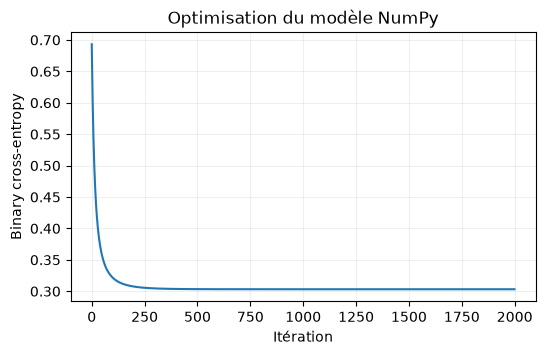

In [ ]:
def logistic_loss(candidate_weights):
    probs = sigmoid(x_train_scaled @ candidate_weights)
    probs = np.clip(probs, 1e-8, 1 - 1e-8)
    return -np.mean(y_train * np.log(probs) + (1 - y_train) * np.log(1 - probs))
initial_weights = np.zeros(x_train_scaled.shape[1])
h = 1e-5
shift = np.array([h, 0.])
numerical_gradient = (logistic_loss(initial_weights + shift) - logistic_loss(initial_weights - shift)) / (2 * h)
analytic_gradient = (x_train_scaled.T @ (sigmoid(x_train_scaled @ initial_weights) - y_train) / len(y_train))[0]
print('dJ/dw0 numérique/analytique :', numerical_gradient, analytic_gradient)
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(losses); ax.set(xlabel='Itération', ylabel='Binary cross-entropy', title='Optimisation du modèle NumPy')
ax.grid(alpha=0.2); plt.show()

## 3. Implémentations de bibliothèque et compromis

Le même split permet une comparaison pédagogique. Scaling est dans chaque pipeline et s’entraîne uniquement sur le train. Les coûts sont des ordres de grandeur dépendant de l’algorithme, implémentation et données.

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, f1_score

models = {
    'logistic': make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    'knn k=15': make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=15)),
    'decision tree': DecisionTreeClassifier(max_depth=5, random_state=11),
    'rbf svm': make_pipeline(StandardScaler(), SVC(C=1.0, gamma='scale')),
    'GaussianNB': GaussianNB(),
    'random forest': RandomForestClassifier(n_estimators=80, max_depth=6, random_state=11),
    'gradient boosting': HistGradientBoostingClassifier(max_iter=80, random_state=11),
}
for name, estimator in models.items():
    estimator.fit(x_train, y_train)
    predicted = estimator.predict(x_test)
    print(name, 'accuracy=', round(accuracy_score(y_test, predicted), 3), 'F1=', round(f1_score(y_test, predicted), 3))

## 4. Visualiser les frontières

La couleur de fond indique la classe prédite en chaque point du plan. Le contour n’est qu’une projection 2D ; un modèle avec plus de variables n’aurait pas un unique graphique équivalent.

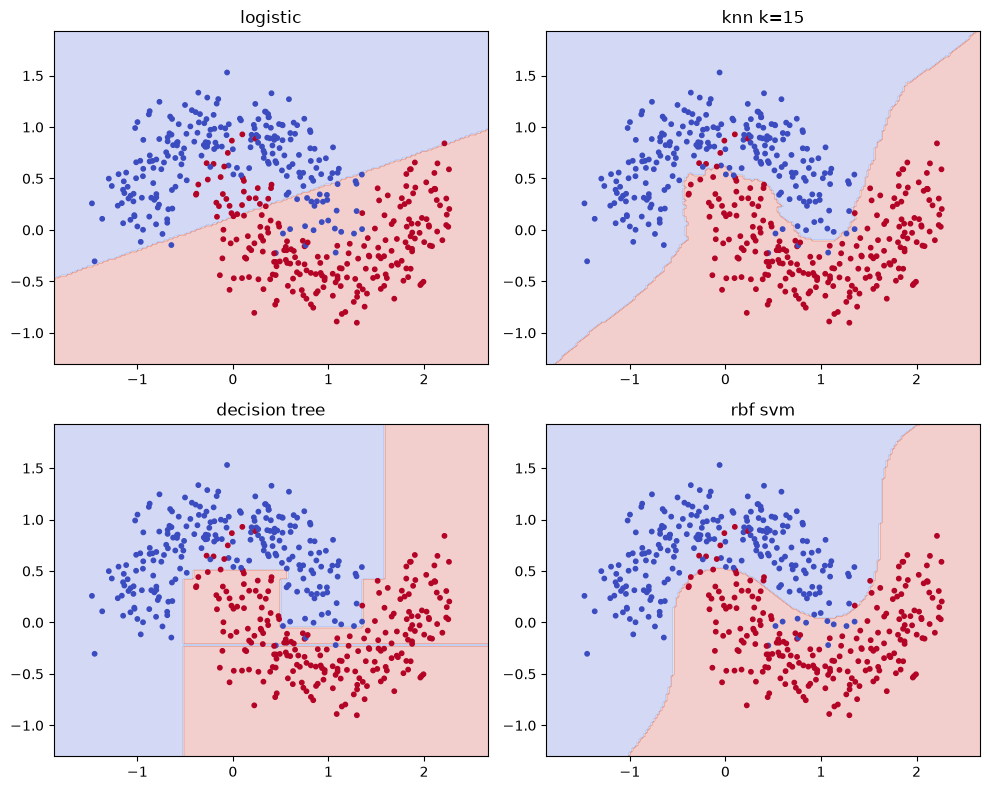

In [ ]:
from matplotlib.colors import ListedColormap

mesh_x, mesh_y = np.meshgrid(np.linspace(x_train[:, 0].min() - 0.4, x_train[:, 0].max() + 0.4, 180), np.linspace(x_train[:, 1].min() - 0.4, x_train[:, 1].max() + 0.4, 180))
mesh = np.c_[mesh_x.ravel(), mesh_y.ravel()]
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
for ax, name in zip(axes.flat, ['logistic', 'knn k=15', 'decision tree', 'rbf svm']):
    prediction_grid = models[name].predict(mesh).reshape(mesh_x.shape)
    ax.contourf(mesh_x, mesh_y, prediction_grid, alpha=0.25, cmap='coolwarm')
    ax.scatter(x_train[:, 0], x_train[:, 1], c=y_train, s=10, cmap='coolwarm')
    ax.set_title(name)
plt.tight_layout(); plt.show()

## 5. Hypothèses, complexité et limites

| Algorithme | Idée/hypothèse utile | Limite pratique fréquente |
|---|---|---|
| Logistic regression | frontière linéaire en features | nécessite feature engineering pour courbure |
| KNN | voisins semblables ont des labels proches | sensible à l’échelle et coûteux à prédire (`O(n·p)`) |
| Decision tree | règles de seuil successives | profondeur excessive sur-apprend |
| SVM RBF | marge avec frontière non linéaire | scaling et choix d’hyperparamètres ; kernel peut coûter cher en `n` |
| Gaussian Naive Bayes | features conditionnellement indépendantes, vraisemblance gaussienne | hypothèse souvent simplificatrice |
| Random Forest | moyenne d'arbres diversifiés pour réduire la variance | mémoire et latence augmentent avec les arbres |
| Gradient Boosting | ajoute des arbres pour corriger progressivement les erreurs | réglages et surapprentissage possibles |

Une seule accuracy et une graine ne classent pas les modèles universellement. Pour continuer : comparer ces modèles par validation croisée, examiner leur calibration, puis passer au [notebook sur K-Means, DBSCAN et PCA](03_unsupervised_clustering_pca.ipynb). Exercices : [`04_models.ipynb`](../../exercises/intermediate/04_models.ipynb).